In [1]:
import numpy as np
import pandas as pd

In [3]:
dataset= pd.read_csv('D:/Github_project/Walmart_Sales.csv')

In [5]:
dataset

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [7]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [9]:
dataset['Date'].unique()

array(['05-02-2010', '12-02-2010', '19-02-2010', '26-02-2010',
       '05-03-2010', '12-03-2010', '19-03-2010', '26-03-2010',
       '02-04-2010', '09-04-2010', '16-04-2010', '23-04-2010',
       '30-04-2010', '07-05-2010', '14-05-2010', '21-05-2010',
       '28-05-2010', '04-06-2010', '11-06-2010', '18-06-2010',
       '25-06-2010', '02-07-2010', '09-07-2010', '16-07-2010',
       '23-07-2010', '30-07-2010', '06-08-2010', '13-08-2010',
       '20-08-2010', '27-08-2010', '03-09-2010', '10-09-2010',
       '17-09-2010', '24-09-2010', '01-10-2010', '08-10-2010',
       '15-10-2010', '22-10-2010', '29-10-2010', '05-11-2010',
       '12-11-2010', '19-11-2010', '26-11-2010', '03-12-2010',
       '10-12-2010', '17-12-2010', '24-12-2010', '31-12-2010',
       '07-01-2011', '14-01-2011', '21-01-2011', '28-01-2011',
       '04-02-2011', '11-02-2011', '18-02-2011', '25-02-2011',
       '04-03-2011', '11-03-2011', '18-03-2011', '25-03-2011',
       '01-04-2011', '08-04-2011', '15-04-2011', '22-04

In [11]:
# High CPI rises, consumer's money buys less
# customer buys essential goods
# Demand of low brand or cheaper products may increase-- as some products customer still wishes to purchase
# Bulk buying may increase - if discount offers
# seasonal demand swing
# Temperature
# mode of purchase may switch - offline to online or viceversa
# holidays

In [13]:
dataset['Weekly_sales']=dataset['Weekly_Sales']

In [15]:
dataset['Weekly_sales']

0       1643690.90
1       1641957.44
2       1611968.17
3       1409727.59
4       1554806.68
           ...    
6430     713173.95
6431     733455.07
6432     734464.36
6433     718125.53
6434     760281.43
Name: Weekly_sales, Length: 6435, dtype: float64

In [17]:
dataset=dataset.drop('Weekly_Sales',axis=1)

In [19]:
dataset

,Store,Date,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekly_sales
0,1,05-02-2010,0,42.31,2.572,211.096358,8.106,1643690.90
1,1,12-02-2010,1,38.51,2.548,211.242170,8.106,1641957.44
2,1,19-02-2010,0,39.93,2.514,211.289143,8.106,1611968.17
3,1,26-02-2010,0,46.63,2.561,211.319643,8.106,1409727.59
4,1,05-03-2010,0,46.50,2.625,211.350143,8.106,1554806.68
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,0,64.88,3.997,192.013558,8.684,713173.95
6431,45,05-10-2012,0,64.89,3.985,192.170412,8.667,733455.07
6432,45,12-10-2012,0,54.47,4.000,192.327265,8.667,734464.36
6433,45,19-10-2012,0,56.47,3.969,192.330854,8.667,718125.53


In [21]:
dataset['Date']=pd.to_datetime(dataset['Date'],dayfirst=True)
Weekly_sales_all_store=dataset.groupby(['Date'])['Weekly_sales'].sum().reset_index().set_index('Date')

In [23]:
Weekly_sales_all_store

,Weekly_sales
Date,
2010-02-05,49750740.50
2010-02-12,48336677.63
2010-02-19,48276993.78
2010-02-26,43968571.13
2010-03-05,46871470.30
...,...
2012-09-28,43734899.40
2012-10-05,47566639.31
2012-10-12,46128514.25


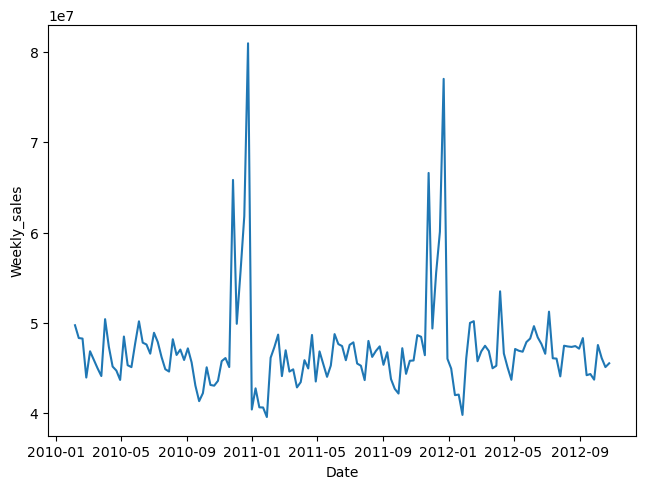

In [25]:
import matplotlib.pyplot as plt
plt.plot(Weekly_sales_all_store.index, Weekly_sales_all_store.values)
plt.tight_layout()
plt.xlabel('Date')
plt.ylabel('Weekly_sales')
plt.show()

In [29]:
store_wise_sale=dataset.groupby(['Store'])['Weekly_sales'].sum().reset_index()
print(store_wise_sale)

    Store  Weekly_sales
0       1  2.224028e+08
1       2  2.753824e+08
2       3  5.758674e+07
3       4  2.995440e+08
4       5  4.547569e+07
5       6  2.237561e+08
6       7  8.159828e+07
7       8  1.299512e+08
8       9  7.778922e+07
9      10  2.716177e+08
10     11  1.939628e+08
11     12  1.442872e+08
12     13  2.865177e+08
13     14  2.889999e+08
14     15  8.913368e+07
15     16  7.425243e+07
16     17  1.277821e+08
17     18  1.551147e+08
18     19  2.066349e+08
19     20  3.013978e+08
20     21  1.081179e+08
21     22  1.470756e+08
22     23  1.987506e+08
23     24  1.940160e+08
24     25  1.010612e+08
25     26  1.434164e+08
26     27  2.538559e+08
27     28  1.892637e+08
28     29  7.714155e+07
29     30  6.271689e+07
30     31  1.996139e+08
31     32  1.668192e+08
32     33  3.716022e+07
33     34  1.382498e+08
34     35  1.315207e+08
35     36  5.341221e+07
36     37  7.420274e+07
37     38  5.515963e+07
38     39  2.074455e+08
39     40  1.378703e+08
40     41  1.813

<Axes: xlabel='Store', ylabel='Weekly_sales'>

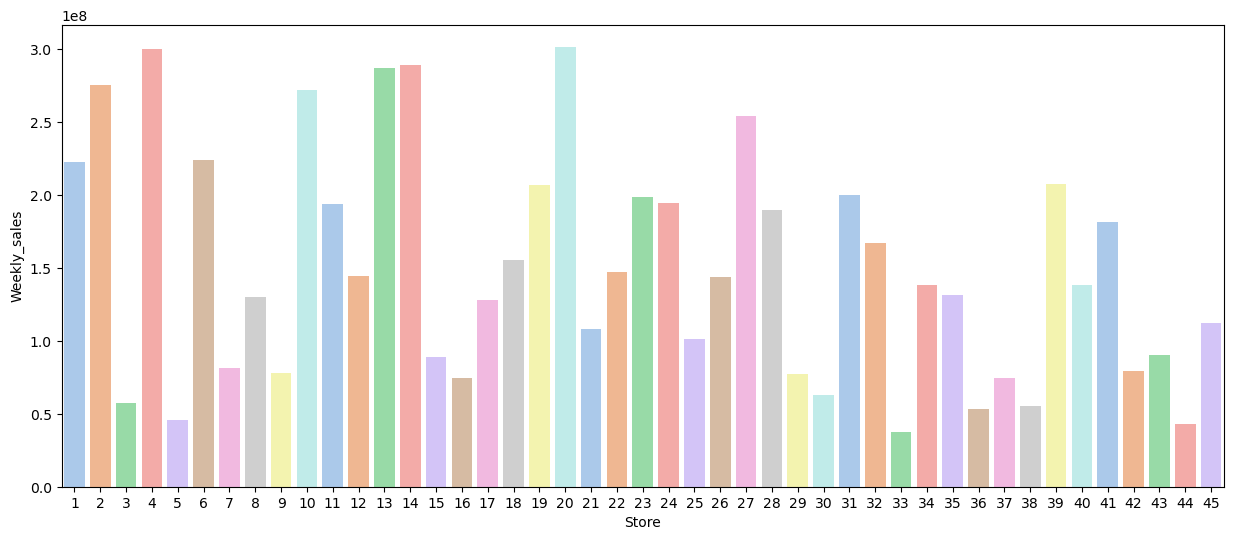

In [31]:
import seaborn as sns
plt.figure(figsize=(15,6))
sns.barplot(data=store_wise_sale,x=store_wise_sale['Store'], y= store_wise_sale['Weekly_sales'],hue='Store',estimator='mean',palette='pastel',legend=False,)

    Store  Weekly_sales
19     20  3.013978e+08
3       4  2.995440e+08
13     14  2.889999e+08
12     13  2.865177e+08
1       2  2.753824e+08
9      10  2.716177e+08
26     27  2.538559e+08
5       6  2.237561e+08
0       1  2.224028e+08
38     39  2.074455e+08
28     29  7.714155e+07
15     16  7.425243e+07
36     37  7.420274e+07
29     30  6.271689e+07
2       3  5.758674e+07
37     38  5.515963e+07
35     36  5.341221e+07
4       5  4.547569e+07
43     44  4.329309e+07
32     33  3.716022e+07


C:\Users\Home\AppData\Local\Temp\ipykernel_29200\3927057747.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=combined,x=combined['Store'], y= combined['Weekly_sales'],palette='coolwarm',legend=False,order=combined['Store'])


<Axes: xlabel='Store', ylabel='Weekly_sales'>

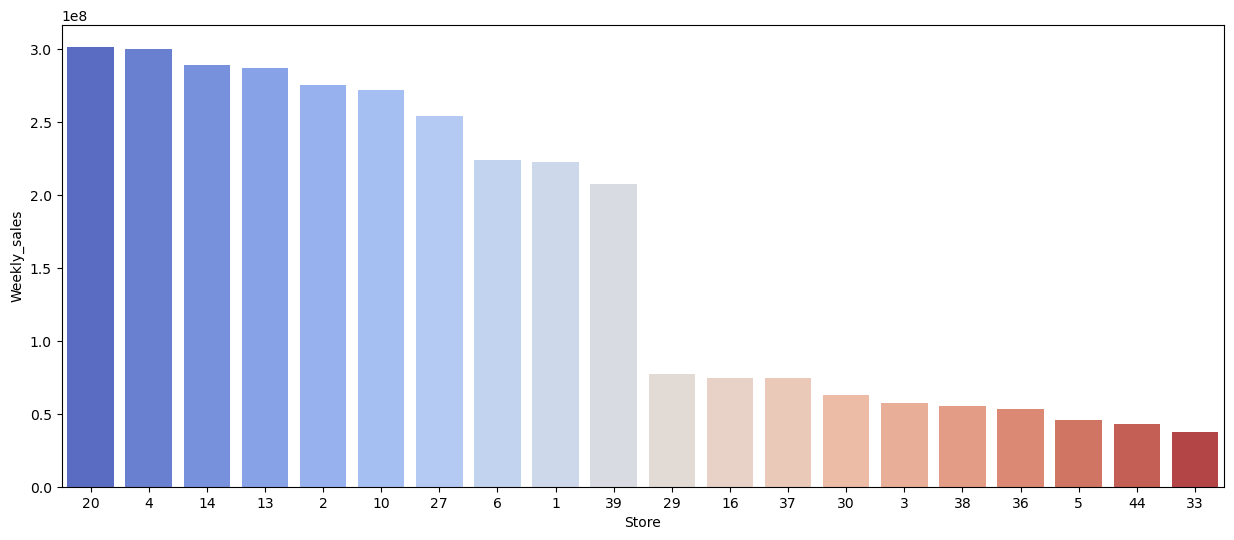

In [37]:
store_wise_sales_1= dataset.groupby(['Store'])['Weekly_sales'].sum().reset_index()
store_wise_sales_1=store_wise_sales_1.sort_values('Weekly_sales',ascending=True)
top=store_wise_sales_1.tail(10)
bottom=store_wise_sales_1.head(10)
combined=pd.concat([top,bottom]).sort_values('Weekly_sales',ascending=False)
print(combined)
#print(store_wise_sales_1)
plt.figure(figsize=(15,6))
sns.barplot(data=combined,x=combined['Store'], y= combined['Weekly_sales'],palette='coolwarm',legend=False,order=combined['Store'])

In [39]:
dataset['month']=dataset['Date'].dt.month
dataset['year']=dataset['Date'].dt.year
dataset

,Store,Date,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekly_sales,month,year
0,1,2010-02-05,0,42.31,2.572,211.096358,8.106,1643690.90,2,2010
1,1,2010-02-12,1,38.51,2.548,211.242170,8.106,1641957.44,2,2010
2,1,2010-02-19,0,39.93,2.514,211.289143,8.106,1611968.17,2,2010
3,1,2010-02-26,0,46.63,2.561,211.319643,8.106,1409727.59,2,2010
4,1,2010-03-05,0,46.50,2.625,211.350143,8.106,1554806.68,3,2010
...,...,...,...,...,...,...,...,...,...,...
6430,45,2012-09-28,0,64.88,3.997,192.013558,8.684,713173.95,9,2012
6431,45,2012-10-05,0,64.89,3.985,192.170412,8.667,733455.07,10,2012
6432,45,2012-10-12,0,54.47,4.000,192.327265,8.667,734464.36,10,2012
6433,45,2012-10-19,0,56.47,3.969,192.330854,8.667,718125.53,10,2012


In [41]:
month_Sale=dataset.groupby('month')['Weekly_sales'].sum().reset_index()
month_Sale

,month,Weekly_sales
0,1,3.325984e+08
1,2,5.687279e+08
2,3,5.927859e+08
3,4,6.468598e+08
4,5,5.571256e+08
5,6,6.226299e+08
6,7,6.500010e+08
7,8,6.130902e+08
8,9,5.787612e+08
9,10,5.847848e+08


C:\Users\Home\AppData\Local\Temp\ipykernel_29200\178959444.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=month_Sale, x=month_Sale['month'], y=month_Sale['Weekly_sales'],palette=color_palette)
C:\Users\Home\AppData\Local\Temp\ipykernel_29200\178959444.py:2: UserWarning: 
The palette list has fewer values (6) than needed (12) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data=month_Sale, x=month_Sale['month'], y=month_Sale['Weekly_sales'],palette=color_palette)


<Axes: xlabel='month', ylabel='Weekly_sales'>

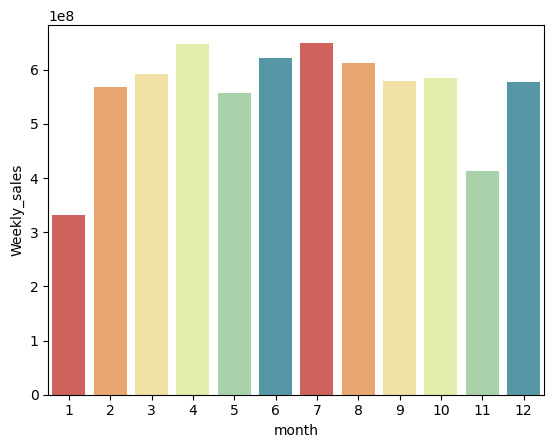

In [43]:
color_palette=sns.color_palette("Spectral")
sns.barplot(data=month_Sale, x=month_Sale['month'], y=month_Sale['Weekly_sales'],palette=color_palette)

C:\Users\Home\AppData\Local\Temp\ipykernel_29200\432303148.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=year_wise_sale, x='year', y='Weekly_sales', palette='muted')


<Axes: xlabel='year', ylabel='Weekly_sales'>

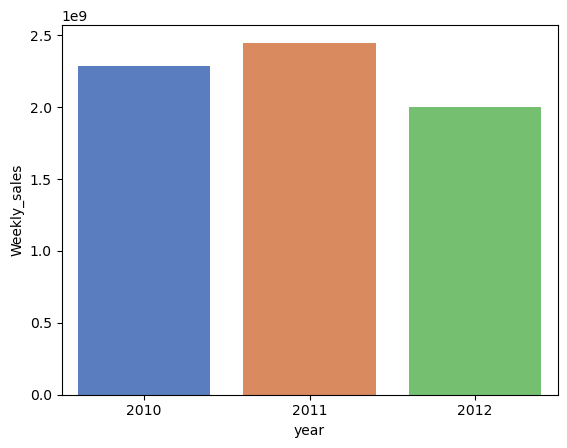

In [45]:
year_wise_sale= dataset.groupby('year')['Weekly_sales'].sum().reset_index()
sns.barplot(data=year_wise_sale, x='year', y='Weekly_sales', palette='muted')

In [47]:
month_year_sale= dataset.groupby(['year','month'])['Weekly_sales'].sum(). reset_index()
print(month_year_sale)
type(month_year_sale)

    year  month  Weekly_sales
0   2010      2  1.903330e+08
1   2010      3  1.819198e+08
2   2010      4  2.314124e+08
3   2010      5  1.867109e+08
4   2010      6  1.922462e+08
5   2010      7  2.325801e+08
6   2010      8  1.876401e+08
7   2010      9  1.772679e+08
8   2010     10  2.171618e+08
9   2010     11  2.028534e+08
10  2010     12  2.887605e+08
11  2011      1  1.637040e+08
12  2011      2  1.863313e+08
13  2011      3  1.793564e+08
14  2011      4  2.265265e+08
15  2011      5  1.816482e+08
16  2011      6  1.897734e+08
17  2011      7  2.299114e+08
18  2011      8  1.885993e+08
19  2011      9  2.208477e+08
20  2011     10  1.832613e+08
21  2011     11  2.101624e+08
22  2011     12  2.880781e+08
23  2012      1  1.688945e+08
24  2012      2  1.920636e+08
25  2012      3  2.315097e+08
26  2012      4  1.889209e+08
27  2012      5  1.887665e+08
28  2012      6  2.406103e+08
29  2012      7  1.875095e+08
30  2012      8  2.368508e+08
31  2012      9  1.806455e+08
32  2012  

pandas.core.frame.DataFrame

<Axes: xlabel='month', ylabel='Weekly_sales'>

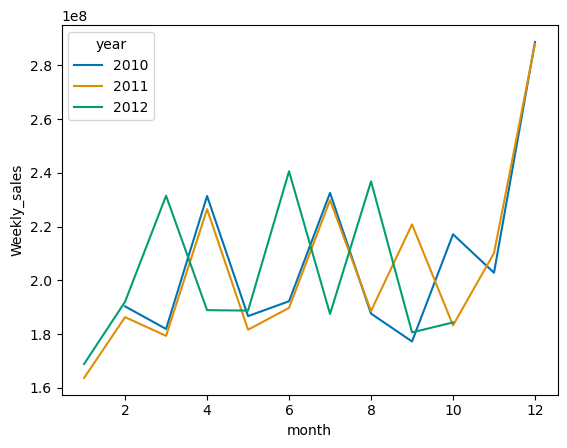

In [49]:
sns.lineplot(data=month_year_sale, x='month', y='Weekly_sales',hue='year', palette='colorblind')

<Axes: xlabel='Holiday_Flag', ylabel='Weekly_sales'>

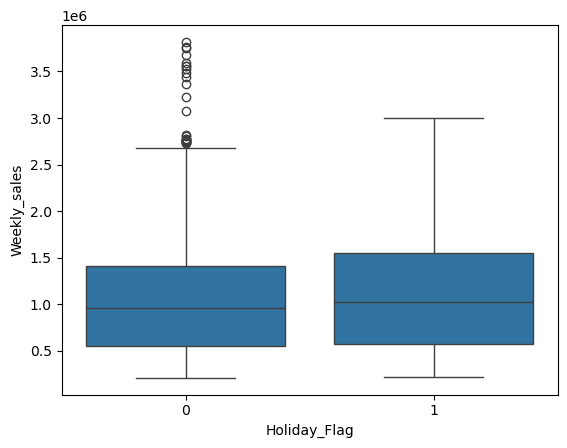

In [51]:
sns.boxplot(data=dataset,x='Holiday_Flag',y='Weekly_sales')

In [59]:
x= dataset.drop(['Weekly_sales','month','year','Date'], axis=1)
y=dataset['Weekly_sales']

In [61]:
x

,Store,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,0,42.31,2.572,211.096358,8.106
1,1,1,38.51,2.548,211.242170,8.106
2,1,0,39.93,2.514,211.289143,8.106
3,1,0,46.63,2.561,211.319643,8.106
4,1,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...
6430,45,0,64.88,3.997,192.013558,8.684
6431,45,0,64.89,3.985,192.170412,8.667
6432,45,0,54.47,4.000,192.327265,8.667
6433,45,0,56.47,3.969,192.330854,8.667


In [63]:
from sklearn.model_selection import train_test_split
X_trains, X_tests, y_trains, y_tests = train_test_split(x, y,  test_size=0.3, random_state = 1)

In [97]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_trains)
X_train_scaled= scaler.transform(X_trains)


In [99]:
X_trains_scaled=pd.DataFrame(X_train_scaled,columns=x.columns)

In [101]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

# Initialize and train model
decision_trees = DecisionTreeRegressor(max_depth=4, random_state=42)
decision_trees.fit(X_trains_scaled, y_trains)



DecisionTreeRegressor(max_depth=4, random_state=42)

In [103]:
X_tests_scaled = scaler.transform(X_tests)



In [109]:
X_tests_scaled_1=pd.DataFrame(X_tests_scaled, columns=x.columns)

In [113]:
y_pred = decision_trees.predict(X_tests_scaled_1)
y_pred_train = decision_trees.predict(X_trains_scaled)

In [115]:
print("R_squared of Decision Trees- test data:", r2_score(y_tests, y_pred))
print("R_squared of Decision Trees- train data:", r2_score(y_trains, y_pred_train))

R_squared of Decision Trees- test data: 0.6312268479208458
R_squared of Decision Trees- train data: 0.617106524681577


In [119]:
number_of_trees = 100  # also, known as number of weak learners in your ensemble model; number of estimators
depth = 4  # Controls the depth of the tree during splitting

In [121]:
from sklearn.ensemble import BaggingRegressor  # Bagging works with all features

# Initialize and train model
bagged_trees = BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=depth),  # max depth controls the depth of the tree (weak learner) during splitting
                                n_estimators=number_of_trees, # number of weak learners in my ensemble
                                random_state=42
)
bagged_trees.fit(X_trains_scaled, y_trains)  # training the bagged trees on subsets of data (100 subsets)

# Predict and evaluate
y_pred = bagged_trees.predict(X_tests_scaled_1)
y_pred_train = bagged_trees.predict(X_trains_scaled)
print("R_squared of Bagged Trees- test data:", r2_score(y_tests, y_pred))
print("R_squared of Bagged Trees- train data:", r2_score(y_trains, y_pred_train))

R_squared of Bagged Trees- test data: 0.6330881372201993
R_squared of Bagged Trees- train data: 0.6208157551078799


In [123]:
from sklearn.ensemble import RandomForestRegressor # RFs work with subset of features

# Initialize and train model
random_forest = RandomForestRegressor(
    n_estimators=number_of_trees, 
    max_depth=depth,
    max_features=5, # essentially indicating that each tree in the ensemble will consider only 7 features when looking for the best split, which introduces randomness and helps in reducing overfitting.
    random_state=42
    )

random_forest.fit(X_trains_scaled, y_trains) # training the RFs on subsets of data and features

# Predict and evaluate
y_pred = random_forest.predict(X_tests_scaled_1) 
y_pred_train = bagged_trees.predict(X_trains_scaled)
print("R_squared of Bagged Trees- test data:", r2_score(y_tests, y_pred))
print("R_squared of Bagged Trees- train data:", r2_score(y_trains, y_pred_train))

R_squared of Bagged Trees- test data: 0.6185254299962668
R_squared of Bagged Trees- train data: 0.6208157551078799


In [125]:
from sklearn.ensemble import AdaBoostRegressor

# Initialize and train model
boosted_trees = AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=depth),
                                  n_estimators=number_of_trees,
                                  random_state=42
)
boosted_trees.fit(X_trains_scaled, y_trains)

# Predict and evaluate
y_pred = boosted_trees.predict(X_tests_scaled_1)
y_pred_train = bagged_trees.predict(X_trains_scaled)
print("R_squared of Bagged Trees- test data:", r2_score(y_tests, y_pred))
print("R_squared of Bagged Trees- train data:", r2_score(y_trains, y_pred_train))

R_squared of Bagged Trees- test data: 0.5105621384367107
R_squared of Bagged Trees- train data: 0.6208157551078799


In [127]:
np.arange(1, 21, 1)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20])

In [129]:
Number_of_Trees = 80  # this is held constant
depth_range = np.arange(1, 21, 1)  # this is varied in a range

rsq_bagged_d_test = []
rsq_bagged_d_train = []
rsq_rforest_d_test = []
rsq_rforest_d_train = []
rsq_boost_d_test = []
rsq_boost_d_train = []

for md in depth_range:
    # Bagged Trees
    bagged_trees_depth = BaggingRegressor(
        DecisionTreeRegressor(max_depth=md),
        n_estimators=Number_of_Trees,
        random_state=42
    )
    bagged_trees_depth.fit(X_trains_scaled, y_trains)
    y_pred_test = bagged_trees_depth.predict(X_tests_scaled_1)
    y_pred_train = bagged_trees_depth.predict(X_trains_scaled)
    r2_test = r2_score(y_tests, y_pred_test)
    r2_train = r2_score(y_trains, y_pred_train)
    rsq_bagged_d_test.append(r2_test)
    rsq_bagged_d_train.append(r2_train)
    
    # Random Forest
    random_forest_depth = RandomForestRegressor(
        n_estimators=Number_of_Trees, 
        max_depth=md,
        random_state=42)
    random_forest_depth.fit(X_trains_scaled, y_trains)
    
    y_pred_test = random_forest_depth.predict(X_tests_scaled_1)
    y_pred_train= random_forest_depth.predict(X_trains_scaled)
    r2_test = r2_score(y_tests, y_pred_test)
    r2_train= r2_score(y_trains, y_pred_train)
    rsq_rforest_d_test.append(r2_test)
    rsq_rforest_d_train.append(r2_train)
    
    # Boosted Trees
    boosted_trees_depth = AdaBoostRegressor(
        DecisionTreeRegressor(max_depth=md),
        n_estimators=Number_of_Trees,
        random_state=42
        )
    boosted_trees_depth.fit(X_trains_scaled, y_trains)
    y_pred_test= boosted_trees_depth.predict(X_tests_scaled_1)
    y_pred_train= boosted_trees_depth.predict(X_trains_scaled)
    r2_test = r2_score(y_tests, y_pred_test)
    r2_train = r2_score(y_trains, y_pred_train)
    rsq_boost_d_test.append(r2_test)
    rsq_boost_d_train.append(r2_train)

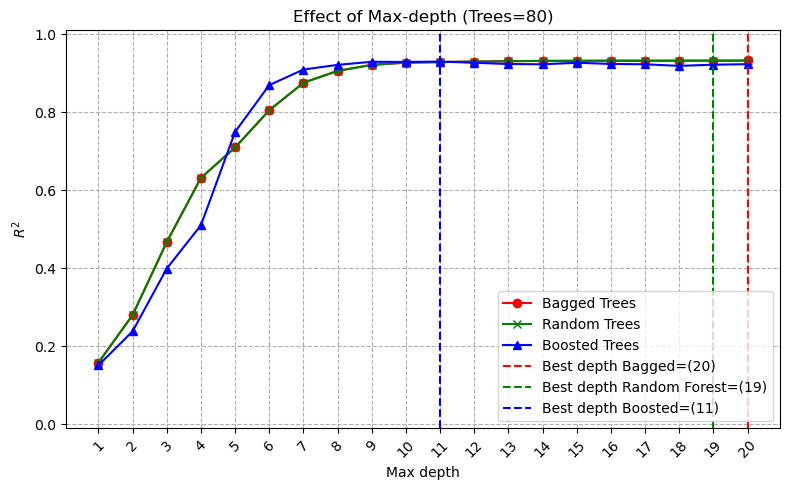

In [131]:
plt.figure(figsize=(8, 5))
plt.plot(depth_range, rsq_bagged_d_test, "-o", color="r", label="Bagged Trees")
plt.plot(depth_range, rsq_rforest_d_test, "-x", color="g", label="Random Trees")
plt.plot(depth_range, rsq_boost_d_test, "-^", color="b", label="Boosted Trees")

best_depth_bagged = depth_range[np.argmax(rsq_bagged_d_test)]  # Best depth for Bagged Trees
best_depth_rforest = depth_range[np.argmax(rsq_rforest_d_test)]  # Best depth for Random Forest
best_depth_boost = depth_range[np.argmax(rsq_boost_d_test)]  # Best depth for Boosted Trees
plt.axvline(best_depth_bagged, color="r", linestyle="--", label=f"Best depth Bagged=({best_depth_bagged})")
plt.axvline(best_depth_rforest, color="g", linestyle="--", label=f"Best depth Random Forest=({best_depth_rforest})")
plt.axvline(best_depth_boost, color="b", linestyle="--", label=f"Best depth Boosted=({best_depth_boost})")

plt.ylim([-0.01, 1.01])
plt.xticks(ticks=depth_range, 
           labels=[str(x) for x in depth_range],
           rotation=45)
plt.ylabel("$R^2$")
plt.xlabel("Max depth")
plt.grid(ls="--")
plt.legend(loc=4)
plt.title(f"Effect of Max-depth (Trees={Number_of_Trees})")
plt.tight_layout()
plt.show()

In [135]:
Max_depth = 7  # this is held constant
Total_estimators = np.arange(1, 201, 20)  # this is varied in a range

rsq_bagged_s = []
rsq_rforest_s = []
rsq_boost_s = []

for nt in Total_estimators:
    # Bagged Trees
    bagged_trees_est = BaggingRegressor(
        DecisionTreeRegressor(max_depth=Max_depth),
        n_estimators=nt,
        random_state=42
    )
    bagged_trees_est.fit(X_trains_scaled, y_trains)
    y_pred = bagged_trees_est.predict(X_tests_scaled_1)
    r2 = r2_score(y_tests, y_pred)
    rsq_bagged_s.append(r2)
    
    # Random Forest
    random_forest_est = RandomForestRegressor(
        n_estimators=nt, 
        max_depth=Max_depth,
        random_state=42)
    random_forest_est.fit(X_trains_scaled, y_trains)
    y_pred = random_forest_est.predict(X_tests_scaled_1)
    r2 = r2_score(y_tests, y_pred)
    rsq_rforest_s.append(r2)
    
    # Boosted Trees
    boosted_trees_est = AdaBoostRegressor(
        DecisionTreeRegressor(max_depth=Max_depth),
        n_estimators=nt,
        random_state=42
        )
    boosted_trees_est.fit(X_trains_scaled, y_trains)
    y_pred = boosted_trees_est.predict(X_tests_scaled_1)
    r2 = r2_score(y_tests, y_pred)
    rsq_boost_s.append(r2)

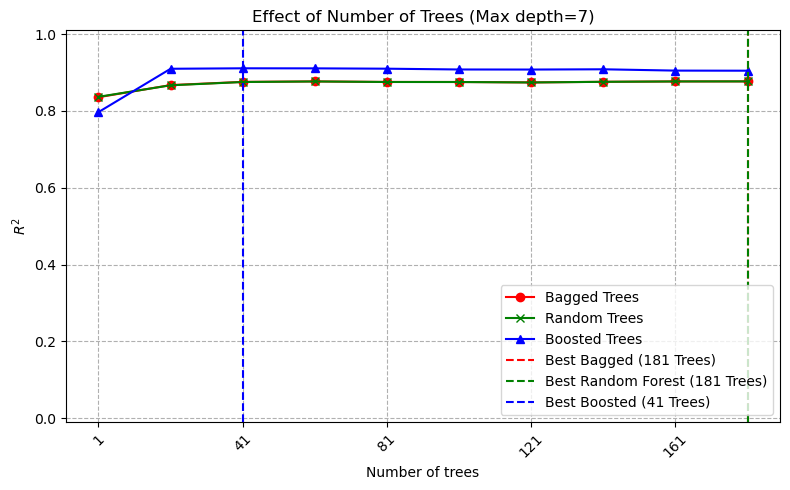

In [137]:
plt.figure(figsize=(8, 5))
plt.plot(Total_estimators, rsq_bagged_s, "-o", color="r", label="Bagged Trees")
plt.plot(Total_estimators, rsq_rforest_s, "-x", color="g", label="Random Trees")
plt.plot(Total_estimators, rsq_boost_s, "-^", color="b", label="Boosted Trees")

best_trees_bagged = Total_estimators[np.argmax(rsq_bagged_s)]  # Best number of trees for Bagged Trees
best_trees_rforest = Total_estimators[np.argmax(rsq_rforest_s)]  # Best number of trees for Random Forest
best_trees_boost = Total_estimators[np.argmax(rsq_boost_s)]  # Best number of trees for Boosted Trees

plt.axvline(best_trees_bagged, color="r", linestyle="--", label=f"Best Bagged ({best_trees_bagged} Trees)")
plt.axvline(best_trees_rforest, color="g", linestyle="--", label=f"Best Random Forest ({best_trees_rforest} Trees)")
plt.axvline(best_trees_boost, color="b", linestyle="--", label=f"Best Boosted ({best_trees_boost} Trees)")

plt.ylim([-0.01, 1.01])
plt.xticks(ticks=Total_estimators[::2], 
           labels=[str(x) for x in Total_estimators[::2]],
           rotation=45)
plt.ylabel("$R^2$")
plt.xlabel("Number of trees")
plt.grid(ls="--")
plt.legend(loc=4)
plt.title(f"Effect of Number of Trees (Max depth={Max_depth})")
plt.tight_layout()
plt.show()

In [147]:
boosted_trees_1 = AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=7),
                                  n_estimators=41,
                                  random_state=42
)
boosted_trees_1.fit(X_trains_scaled, y_trains)

# Predict and evaluate
y_pred = boosted_trees_1.predict(X_tests_scaled_1)
y_pred_train = boosted_trees_1.predict(X_trains_scaled)
print("R_squared of Bagged Trees- test data:", r2_score(y_tests, y_pred))
print("R_squared of Bagged Trees- train data:", r2_score(y_trains, y_pred_train))

R_squared of Bagged Trees- test data: 0.911115018560877
R_squared of Bagged Trees- train data: 0.9547200388255314
